<a href="https://colab.research.google.com/github/guptaharshg1171-prog/project_01-hcl-tech/blob/main/Harsh_Gupta_(2026B15410155).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales Performance Analysis
**Student:** Harsh Gupta  
**Admission No.:** 2026B15410155  
**Program:** Data Analytics  
**Project:** Project 1 — Retail Sales Performance Analysis  

This notebook explores retail transactions using Python, NumPy and Pandas. The dataset is synthetic and created for this student project. Results are descriptive and should not be treated as proof of causes.

## 1. Load and inspect dataset

In [ ]:
# Student: Harsh Gupta | Admission No.: 2026B15410155 | Program: Data Analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = Path.cwd()
DATA_PATH = ROOT / "01_retail_sales.csv"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Original dataset shape:", df.shape)
display(df.head())
print("\nColumns and data types:")
display(df.dtypes.to_frame("Data Type"))
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Count"))
print("\nDuplicate Order_ID count:", df["Order_ID"].duplicated().sum())

FileNotFoundError: [Errno 2] No such file or directory: '/content/01_retail_sales.csv'

## Clean duplicate orders using Order_ID (keep first occurrence).

In [ ]:
# Clean duplicate orders using Order_ID (keep first occurrence).
df = df.drop_duplicates(subset="Order_ID", keep="first").copy()

## Fill missing City values with the most frequent city (mode), preserving categorical consistency.

In [ ]:
# Fill missing City values with the most frequent city (mode), preserving categorical consistency.
city_mode = df["City"].mode(dropna=True)[0]
df["City"] = df["City"].fillna(city_mode)

## Parse date safely and add time-based features.

In [ ]:
# Parse date safely and add time-based features.
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%B")
df["Weekday"] = df["Order_Date"].dt.day_name()

## Recalculate revenue and compare against the supplied Revenue column.

In [ ]:
# Recalculate revenue and compare against the supplied Revenue column.
df["Calculated_Revenue"] = df["Quantity"] * df["Unit_Price"]
df["Revenue_Difference"] = df["Revenue"] - df["Calculated_Revenue"]
revenue_mismatch_count = (df["Revenue_Difference"].abs() > 0.01).sum()
df["Revenue"] = df["Calculated_Revenue"]

print("Cleaned dataset shape:", df.shape)
print("Filled missing City values with mode:", city_mode)
print("Revenue mismatches before correction:", revenue_mismatch_count)

Cleaned dataset shape: (500, 15)
Filled missing City values with mode: Bengaluru
Revenue mismatches before correction: 0


## KPI summary

In [ ]:
# KPI summary
total_revenue = df["Revenue"].sum()
total_quantity = df["Quantity"].sum()
average_order_value = total_revenue / df["Order_ID"].nunique()
kpi_summary = pd.DataFrame({
    "Metric": ["Total Revenue", "Total Quantity", "Average Order Value", "Unique Orders"],
    "Value": [total_revenue, total_quantity, average_order_value, df["Order_ID"].nunique()]
})
display(kpi_summary)

,Metric,Value
0,Total Revenue,13954120.00
1,Total Quantity,1480.00
2,Average Order Value,27908.24
3,Unique Orders,500.00


## Top 10 products by revenue

In [ ]:
# Top 10 products by revenue
top_products = df.groupby("Product", as_index=False)["Revenue"].sum().sort_values("Revenue", ascending=False).head(10)
display(top_products)

,Product,Revenue
1,Keyboard,3438656
0,Headphones,2815469
2,Laptop,2371954
4,Mouse,2370572
5,Webcam,1588503
3,Monitor,1368966


## City revenue ranking

In [ ]:
# City revenue ranking
city_revenue = df.groupby("City", as_index=False)["Revenue"].sum().sort_values("Revenue", ascending=False)
display(city_revenue)

,City,Revenue
0,Bengaluru,3311943
1,Delhi,3233684
4,Pune,2881694
2,Hyderabad,2620717
3,Mumbai,1906082


## Monthly revenue and best month

In [ ]:
# Monthly revenue and best month
monthly_revenue = df.groupby(["Month", "Month_Name"], as_index=False)["Revenue"].sum().sort_values("Month")
best_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmax()]
display(monthly_revenue)
print("Best month:", best_month["Month_Name"], "| Revenue:", round(best_month["Revenue"], 2))

,Month,Month_Name,Revenue
0,1,January,1968531
1,2,February,2003009
2,3,March,1212209
3,4,April,1407122
4,5,May,1179881
5,6,June,431919
6,7,July,624525
7,8,August,1144377
8,9,September,895804
9,10,October,1060301


Best month: February | Revenue: 2003009


## Top 10 customers by total spending

In [ ]:
# Top 10 customers by total spending
top_customers = df.groupby("Customer_ID", as_index=False)["Revenue"].sum().sort_values("Revenue", ascending=False).head(10)
display(top_customers)

,Customer_ID,Revenue
13,C0018,445986
38,C0043,425985
29,C0034,392985
134,C0144,376884
77,C0083,321993
154,C0165,302491
122,C0132,278984
140,C0150,277986
67,C0073,269084
48,C0053,248991


## Payment method comparison: order count and revenue

In [ ]:
# Aggregating on the correct column name: 'Payment_Mode'
column_to_group = "Payment_Mode"

payment_summary = df.groupby(column_to_group).agg(
    Order_Count=("Order_ID", "nunique"),
    Total_Revenue=("Revenue", "sum"),
    Average_Order_Value=("Revenue", "mean")
).sort_values("Total_Revenue", ascending=False)

display(payment_summary)

# Ensure category_summary is defined as well for downstream code
category_summary = df.groupby("Category").agg(
    Orders=("Order_ID", "nunique"),
    Quantity=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Avg_Revenue_Per_Order=("Revenue", "mean")
).sort_values("Revenue", ascending=False)


,Order_Count,Total_Revenue,Average_Order_Value
Payment_Mode,,,
UPI,134,4246098,31687.298507
Card,110,3601671,32742.463636
Cash,137,3599772,26275.708029
NetBanking,119,2506579,21063.689076


## Outliers using IQR on order revenue

In [ ]:
# Outliers using IQR on order revenue
q1 = df["Revenue"].quantile(0.25)
q3 = df["Revenue"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
revenue_outliers = df[(df["Revenue"] < lower_bound) | (df["Revenue"] > upper_bound)].sort_values("Revenue", ascending=False)
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f}; outlier records: {len(revenue_outliers)}")
display(revenue_outliers.head(15))

IQR bounds: -52503.00 to 93897.00; outlier records: 32


,Order_ID,Order_Date,City,Product,Category,Quantity,Unit_Price,Customer_ID,Payment_Mode,Revenue,Month,Month_Name,Weekday,Calculated_Revenue,Revenue_Difference
0,ORD00000,2025-02-14,Delhi,Headphones,Accessories,5,45999,C0140,UPI,229995,2,February,Friday,229995,0
13,ORD00013,2026-01-16,Hyderabad,Mouse,Electronics,5,45999,C0132,UPI,229995,1,January,Friday,229995,0
34,ORD00034,2026-03-20,Bengaluru,Laptop,Accessories,5,45999,C0018,UPI,229995,3,March,Friday,229995,0
217,ORD00217,2025-02-18,Bengaluru,Headphones,Electronics,5,45999,C0077,Card,229995,2,February,Tuesday,229995,0
147,ORD00147,2025-04-27,Bengaluru,Headphones,Accessories,5,45999,C0150,Cash,229995,4,April,Sunday,229995,0
131,ORD00131,2025-10-04,Mumbai,Headphones,Accessories,5,45999,C0083,Cash,229995,10,October,Saturday,229995,0
104,ORD00104,2026-02-03,Hyderabad,Mouse,Electronics,5,45999,C0126,NetBanking,229995,2,February,Tuesday,229995,0
97,ORD00097,2025-12-08,Pune,Headphones,Accessories,5,45999,C0057,Cash,229995,12,December,Monday,229995,0
158,ORD00158,2025-09-10,Delhi,Keyboard,Accessories,5,45999,C0120,Card,229995,9,September,Wednesday,229995,0
331,ORD00331,2025-07-05,Mumbai,Headphones,Accessories,5,45999,C0153,UPI,229995,7,July,Saturday,229995,0


## Category-level summary

In [ ]:
# Category-level summary
category_summary = df.groupby("Category").agg(
    Orders=("Order_ID", "nunique"),
    Quantity=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Avg_Revenue_Per_Order=("Revenue", "mean")
).sort_values("Revenue", ascending=False)
display(category_summary)

,Orders,Quantity,Revenue,Avg_Revenue_Per_Order
Category,,,,
Accessories,240,721,7492779,31219.912500
Electronics,260,759,6461341,24851.311538


## NumPy descriptive statistics

In [ ]:
# NumPy descriptive statistics
order_revenue = df["Revenue"].to_numpy()
numpy_stats = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Standard Deviation"],
    "Value": [np.mean(order_revenue), np.median(order_revenue), np.std(order_revenue)]
})
display(numpy_stats)

,Statistic,Value
0,Mean,27908.240000
1,Median,4998.000000
2,Standard Deviation,47698.762747


## Visualizations (saved to outputs)

<Figure size 1000x500 with 0 Axes>

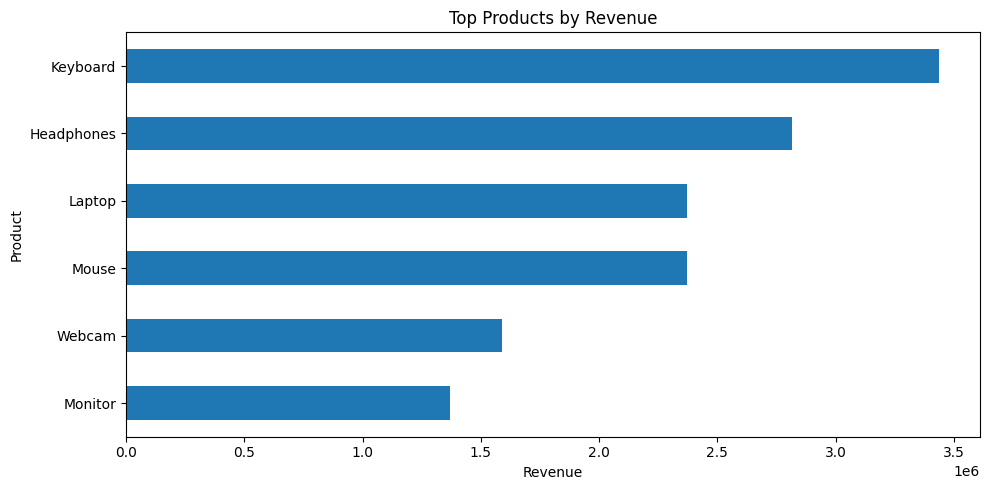

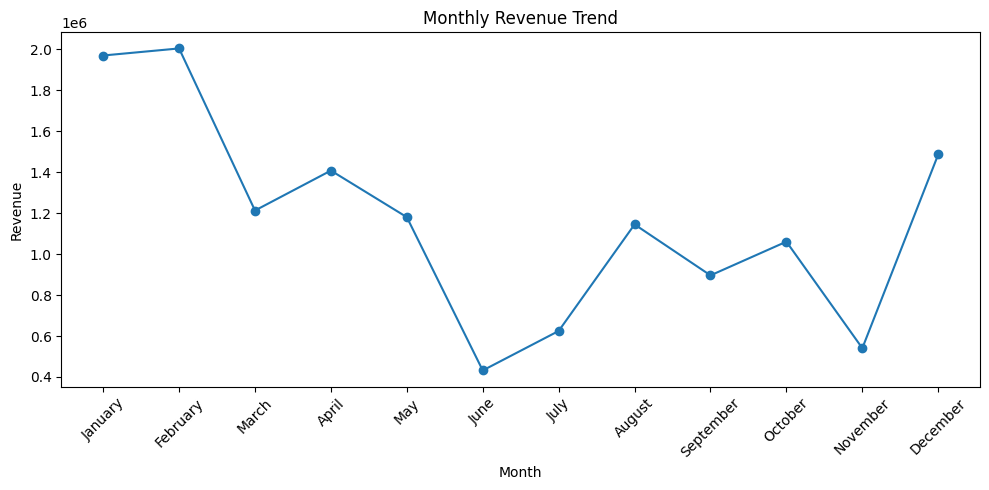

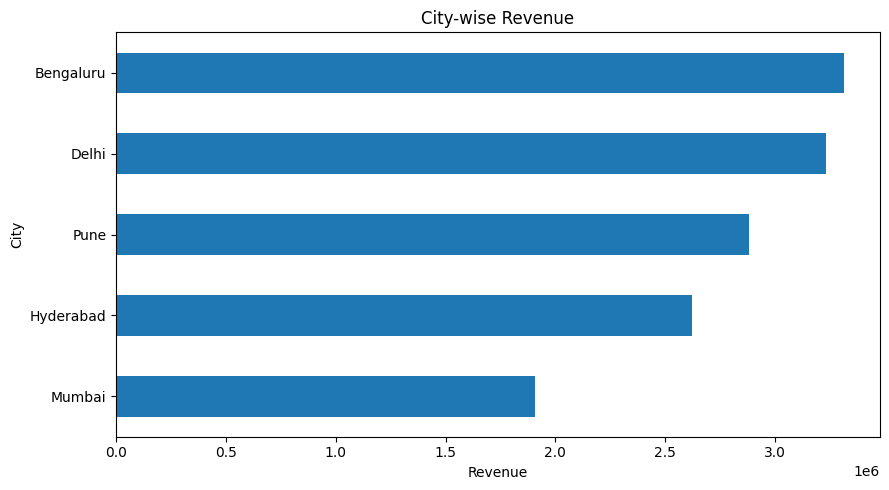

In [ ]:
# Visualizations (saved to outputs)
plt.figure(figsize=(10, 5))
top_products.sort_values("Revenue").plot(kind="barh", x="Product", y="Revenue", legend=False, figsize=(10, 5))
plt.title("Top Products by Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_products_revenue.png", dpi=150)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue["Month_Name"], monthly_revenue["Revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_revenue_trend.png", dpi=150)
plt.show()

city_revenue.sort_values("Revenue").plot(kind="barh", x="City", y="Revenue", legend=False, figsize=(9, 5))
plt.title("City-wise Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "city_revenue.png", dpi=150)
plt.show()

## Save cleaned data and analysis tables

In [ ]:
# Ensure payment_summary is safely generated using the correct column 'Payment_Mode' if not already defined
if "payment_summary" not in globals() and "Payment_Mode" in df.columns:
    payment_summary = df.groupby("Payment_Mode").agg(
        Order_Count=("Order_ID", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Average_Order_Value=("Revenue", "mean")
    ).sort_values("Total_Revenue", ascending=False)

# Save cleaned data and analysis tables
df.to_csv(OUTPUT_DIR / "cleaned_retail_sales.csv", index=False)
tables = {
    "top_products.csv": top_products,
    "city_revenue.csv": city_revenue,
    "monthly_revenue.csv": monthly_revenue,
    "top_customers.csv": top_customers,
    "payment_summary.csv": payment_summary,
    "category_summary.csv": category_summary,
    "revenue_outliers.csv": revenue_outliers,
    "kpi_summary.csv": kpi_summary,
}
for filename, table in tables.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)


## Recommendations are based on the computed tables; review actual results before finalizing.

In [ ]:
# Recommendations are based on the computed tables; review actual results before finalizing.
print("Analysis complete. Tables and cleaned data saved in outputs/.")

Analysis complete. Tables and cleaned data saved in outputs/.


## 14. Evidence-based recommendations

In [ ]:
# Evidence-based recommendations (generated from the computed results)
best_category = category_summary.index[0]
best_city = city_revenue.iloc[0]["City"]
best_payment = payment_summary.index[0]
best_product = top_products.iloc[0]["Product"]
print("1. Review inventory planning for the top revenue-generating category:", best_category)
print("2. Study city-level demand and delivery/inventory coverage in the highest-revenue city:", best_city)
print("3. Keep the top revenue product visible in promotions while monitoring stock:", best_product)
print("4. Ensure checkout/payment experience is reliable for the leading revenue payment method:", best_payment)
print("5. Review the flagged high/low revenue outlier orders before using them for business decisions; IQR flags are not automatically errors.")


1. Review inventory planning for the top revenue-generating category: Accessories
2. Study city-level demand and delivery/inventory coverage in the highest-revenue city: Bengaluru
3. Keep the top revenue product visible in promotions while monitoring stock: Keyboard
4. Ensure checkout/payment experience is reliable for the leading revenue payment method: UPI
5. Review the flagged high/low revenue outlier orders before using them for business decisions; IQR flags are not automatically errors.
